<a href="https://colab.research.google.com/github/Elvirose/CampusAI/blob/main/ai_nlp_campus_fireexit_connection_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Intelligent Campus Navigation**

## *Problem Statement*

Develop an AI navigation agent capable of finding routes between classrooms, laboratories, libraries, offices, and other facilities in a multi-floor engineering college. The agent represents each state as (Building, Floor, Room) and considers stairs, elevators, walking distance, accessibility requirements, closed corridors, and time-dependent congestion. The objective is to find an optimal route by minimizing the total navigation cost.

## *PEAS Description*

**P — Performance Measure:** The agent aims to find the lowest-cost route between the starting location and destination by minimizing walking distance and floor-transition costs while considering accessibility, closed corridors, and congestion.

**E — Environment:** A multi-floor engineering college consisting of classrooms, laboratories, libraries, offices, corridors, staircases, elevators, and other campus facilities.

**A — Actuators:** The agent displays the recommended route, provides navigation instructions, highlights the route on a campus map, indicates floor changes, and suggests alternative routes when necessary.

**S — Sensors:** The agent uses the user's starting location and destination, campus floor-plan data, room and corridor connections, estimated walking distances, lift and staircase locations, corridor closure information, accessibility requirements, and congestion data when available.

## *State Representation*

The state of the navigation agent is represented as:

**State = (Building, Floor, Room)**

For example, a state may represent the Simulation Lab on the second floor of Ramanujan Block.

## *Cost Function*

The navigation objective is represented as:

**Cost = α(distance) + β(floor)**

Here, α represents the weight assigned to walking distance, while β represents the weight assigned to floor transitions. The model can be extended to include congestion and accessibility constraints. Closed corridors are excluded from route selection.

## *Search Algorithms*

The project implements Breadth-First Search (BFS), Depth-First Search (DFS), Uniform Cost Search (UCS), Greedy Best-First Search, and A* Search to find and compare routes in a multi-floor state space.

## Cell 1 — Import libraries

We use pandas to store room and connection tables, Matplotlib to plot a schematic, and heapq/deque for the search algorithms.

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import heapq
import time
import json
from collections import deque
from IPython.display import display

## Cell 2 — Define the assumed dimensions

These dimensions are adjustable assumptions. The room capacities help us choose plausible room sizes, but capacity alone cannot establish the actual room geometry.

In [139]:
ROOM_DIMENSIONS = {
    "classroom": (12.0, 8.0),
    "lab": (8.0, 6.0),
    "hall": (14.0, 10.0),
    "library": (8.0, 6.0),
    "faculty": (5.0, 4.0),
    "room": (5.0, 4.0),
    "toilet": (4.0, 3.0),
    "utility": (3.0, 2.0),
    "lift": (2.5, 2.5),
    "stairs": (5.0, 4.0),
    "exit": (3.0, 3.0),
    "bridge": (5.0, 3.0),
}
CORRIDOR_WIDTH_M = 3.0

## Cell 3 — Enter the locations from the floor-plan legends

Each numbered room keeps the number shown in its floor-plan legend. `x_m` and `y_m` are approximate schematic coordinates, not measured coordinates.

In [140]:
floor2_rooms = [
    (1, "Fire Exit", "exit", "north"),
    (2, "Ladies Toilet", "toilet", "north"),
    (3, "Association Room - CSE", "room", "north"),
    (4, "Simulation Lab", "lab", "north"),
    (5, "EEE Department Library", "library", "north"),
    (6, "Microprocessor & Microcontroller Lab", "lab", "north"),
    (7, "Michael Faraday Hall", "hall", "north"),
    (8, "Electrical Measurements Lab", "lab", "north"),
    (9, "Steve Jobs Hall", "hall", "north"),
    (10, "Classroom M.Tech CSE S1/S2", "classroom", "north"),
    (11, "Codd Base Lab", "lab", "north"),
    (12, "Gents Toilet", "toilet", "north"),
    (13, "Lift 1", "lift", "north"),
    (14, "Staircase 1", "stairs", "north"),
    (15, "Ceaser Lab", "lab", "south"),
    (16, "Grace Hopper Lab", "lab", "south"),
    (17, "Way to Connection Bridge", "bridge", "south"),
    (18, "Turing Lab", "lab", "south"),
    (19, "CSE Faculty Room", "faculty", "south"),
    (20, "Lift 2", "lift", "south"),
    (21, "Staircase 2", "stairs", "south"),
    (22, "Electrical Room", "utility", "south"),
    (23, "Toilet for Handicapped", "toilet", "south"),
    (24, "Passage", "corridor", "center"),
]

floor3_rooms = [
    (1, "Fire Exit", "exit", "north"),
    (2, "Gents Toilet", "toilet", "north"),
    (3, "CSE Department Library", "library", "north"),
    (4, "S5/S6 CSE-B Classroom", "classroom", "north"),
    (5, "Singulary Lab", "lab", "north"),
    (6, "S5/S6 Cyber Security Classroom", "classroom", "north"),
    (7, "S7/S8 CSE-A Classroom", "classroom", "north"),
    (8, "CSE Faculty Room", "faculty", "north"),
    (9, "Shannon Lab", "lab", "north"),
    (10, "S3/S4 CSE(AI)-B Classroom", "classroom", "north"),
    (11, "Elective Classroom", "classroom", "north"),
    (12, "Ladies Toilet", "toilet", "north"),
    (13, "Lift 1", "lift", "north"),
    (14, "Staircase 1", "stairs", "north"),
    (15, "Neumann Lab", "lab", "south"),
    (16, "FOSS Lab", "lab", "south"),
    (17, "CSE Faculty Room 2", "faculty", "south"),
    (18, "Lift 2", "lift", "south"),
    (19, "Staircase 2", "stairs", "south"),
    (20, "Electrical Room", "utility", "south"),
    (21, "Toilet for Handicapped", "toilet", "south"),
    (22, "Passage", "corridor", "center"),
]

## Cell 4 — Create approximate coordinates

The long central corridor is modelled as a sequence of junctions. Rooms on each side connect to their nearest junction. This gives the search algorithms a usable graph without pretending we have an exact architectural scale.

In [141]:
def build_floor(floor_number, rooms, north_start=8.0, spacing=10.0):
    locations = []
    edges = []

    north_rooms = [
        r for r in rooms if r[3] == "north" and r[2] != "corridor"
    ]
    south_rooms = [r for r in rooms if r[3] == "south"]
    passage = next(r for r in rooms if r[2] == "corridor")

    # Create north-side rooms
    for i, (num, name, typ, side) in enumerate(north_rooms):
        x = north_start + i * spacing
        width, height = ROOM_DIMENSIONS[typ]

        locations.append({
            "id": f"{floor_number}F_{num:02d}",
            "floor": floor_number,
            "number": num,
            "name": name,
            "type": typ,
            "x_m": x,
            "y_m": 1.5 + height / 2,
            "width_m": width,
            "height_m": height,
            "source": "Capacity-based assumed size; schematic position"
        })

    # Create south-side rooms
    for i, (num, name, typ, side) in enumerate(south_rooms):
        x = 18.0 + i * 11.0
        width, height = ROOM_DIMENSIONS[typ]

        locations.append({
            "id": f"{floor_number}F_{num:02d}",
            "floor": floor_number,
            "number": num,
            "name": name,
            "type": typ,
            "x_m": x,
            "y_m": -(1.5 + height / 2),
            "width_m": width,
            "height_m": height,
            "source": "Capacity-based assumed size; schematic position"
        })

    # Create corridor junctions
    max_x = max(
        [r["x_m"] for r in locations] + [north_start]
    ) + 5

    junction_count = int(max_x // spacing) + 1
    junctions = []

    for i in range(junction_count):
        x = 5.0 + i * spacing
        jid = f"{floor_number}F_J{i+1:02d}"
        junctions.append((jid, x))

        locations.append({
            "id": jid,
            "floor": floor_number,
            "number": None,
            "name": f"Passage Junction {i+1}",
            "type": "corridor_junction",
            "x_m": x,
            "y_m": 0.0,
            "width_m": CORRIDOR_WIDTH_M,
            "height_m": CORRIDOR_WIDTH_M,
            "source": "Assumed 3 m-wide passage; schematic junction"
        })

        if i > 0:
            previous_id, previous_x = junctions[i - 1]

            edges.append({
                "from_id": previous_id,
                "to_id": jid,
                "distance_m": abs(x - previous_x),
                "edge_type": "corridor",
                "accessible": True,
                "closed": False,
                "verified": False,
                "notes": "Approximate corridor segment; not measured"
            })

    # Optional manual overrides: assumptions, not verified entrances
    room_junction_overrides = {
        "2F_04": "2F_J06",
        "2F_05": "2F_J06",
    }

    # Connect each room to a corridor junction
    for loc in locations.copy():
        if loc["floor"] != floor_number:
            continue

        if loc["type"] != "corridor_junction":
            if loc["type"] == "passage_label":
                continue

            if loc["id"] in room_junction_overrides:
                nearest_id = room_junction_overrides[loc["id"]]
            else:
                nearest_id, nearest_x = min(
                    junctions,
                    key=lambda j: abs(j[1] - loc["x_m"])
                )

            junction_x = next(
                x for jid, x in junctions if jid == nearest_id
            )

            # Approximate room-to-passage walking distance
            distance = abs(loc["y_m"]) + abs(loc["x_m"] - junction_x)

            edges.append({
                "from_id": loc["id"],
                "to_id": nearest_id,
                "distance_m": max(distance, 0.1),
                "edge_type": "room_access",
                "accessible": True,
                "closed": False,
                "verified": False,
                "notes": "Estimated connection; entrance location unverified"
            })

    # Add the passage label once, outside the room loop
    passage_id = f"{floor_number}F_{passage[0]:02d}"
    midpoint = min(
        junctions,
        key=lambda j: abs(j[1] - max_x / 2)
    )

    locations.append({
        "id": passage_id,
        "floor": floor_number,
        "number": passage[0],
        "name": passage[1],
        "type": "passage_label",
        "x_m": midpoint[1],
        "y_m": 0.0,
        "width_m": CORRIDOR_WIDTH_M,
        "height_m": 3.0,
        "source": "Label from supplied floor-plan legend"
    })

    edges.append({
        "from_id": passage_id,
        "to_id": midpoint[0],
        "distance_m": 0.1,
        "edge_type": "corridor",
        "accessible": True,
        "closed": False,
        "verified": False,
        "notes": "Passage label linked to schematic junction"
    })

    return (
        pd.DataFrame(locations).drop_duplicates("id"),
        pd.DataFrame(edges).drop_duplicates(["from_id", "to_id"])
    )


# Build both floors
locations2, connections2 = build_floor(2, floor2_rooms)
locations3, connections3 = build_floor(3, floor3_rooms)

locations = pd.concat(
    [locations2, locations3], ignore_index=True
)

connections = pd.concat(
    [connections2, connections3], ignore_index=True
)

print("Locations:", locations.shape)
print("Connections:", connections.shape)

display(locations.head())
display(connections.head())

Locations: (76, 10)
Connections: (74, 8)


,id,floor,number,name,type,x_m,y_m,width_m,height_m,source
0,2F_01,2,1.0,Fire Exit,exit,8.0,3.0,3.0,3.0,Capacity-based assumed size; schematic position
1,2F_02,2,2.0,Ladies Toilet,toilet,18.0,3.0,4.0,3.0,Capacity-based assumed size; schematic position
2,2F_03,2,3.0,Association Room - CSE,room,28.0,3.5,5.0,4.0,Capacity-based assumed size; schematic position
3,2F_04,2,4.0,Simulation Lab,lab,38.0,4.5,8.0,6.0,Capacity-based assumed size; schematic position
4,2F_05,2,5.0,EEE Department Library,library,48.0,4.5,8.0,6.0,Capacity-based assumed size; schematic position


,from_id,to_id,distance_m,edge_type,accessible,closed,verified,notes
0,2F_J01,2F_J02,10.0,corridor,True,False,False,Approximate corridor segment; not measured
1,2F_J02,2F_J03,10.0,corridor,True,False,False,Approximate corridor segment; not measured
2,2F_J03,2F_J04,10.0,corridor,True,False,False,Approximate corridor segment; not measured
3,2F_J04,2F_J05,10.0,corridor,True,False,False,Approximate corridor segment; not measured
4,2F_J05,2F_J06,10.0,corridor,True,False,False,Approximate corridor segment; not measured


## Cell 5 — Connect matching lifts and staircases between floors

The drawings show two lifts and two staircases on each floor. We connect matching numbered facilities as a **provisional assumption**. Lift/stair costs here are simplified travel costs, not surveyed path lengths.

### Added connection: Floor 2 Fire Exit ↔ Floor 3 Fire Exit

A provisional graph edge connects `2F_01` (Fire Exit, Floor 2) to `3F_01` (Fire Exit, Floor 3). The 5.0 m cost is only a placeholder for route-search testing, not a measured distance. Confirm the actual stair/exit arrangement and distance from the building's approved plan before relying on this for real navigation or emergency use.

In [142]:
# Connect rooms on the 2nd and 3rd floors using lifts and stairs

vertical_connections = [
    {
        "from_id": "2F_13",
        "to_id": "3F_13",
        "distance_m": 4.0,
        "edge_type": "lift",
        "accessible": True,
        "closed": False,
        "verified": False,
        "notes": "Assumed lift connection"
    },
    {
        "from_id": "2F_20",
        "to_id": "3F_18",
        "distance_m": 4.0,
        "edge_type": "lift",
        "accessible": True,
        "closed": False,
        "verified": False,
        "notes": "Assumed lift connection"
    },
    {
        "from_id": "2F_14",
        "to_id": "3F_14",
        "distance_m": 5.0,
        "edge_type": "stairs",
        "accessible": False,
        "closed": False,
        "verified": False,
        "notes": "Assumed staircase connection"
    },
    {
        "from_id": "2F_21",
        "to_id": "3F_19",
        "distance_m": 5.0,
        "edge_type": "stairs",
        "accessible": False,
        "closed": False,
        "verified": False,
        "notes": "Assumed staircase connection"
    },
    {
        "from_id": "2F_01",
        "to_id": "3F_01",
        "distance_m": 5.0,
        "edge_type": "fire_exit_stairs",
        "accessible": False,
        "closed": False,
        "verified": False,
        "notes": "Provisional direct connection between Floor 2 and Floor 3 fire exits; replace 5.0 m with a measured distance and verify against the actual building/fire-safety plan."
    }
]

vertical_connections_df = pd.DataFrame(vertical_connections)

connections = pd.concat(
    [connections, vertical_connections_df],
    ignore_index=True
)

print("Vertical connections added:", len(vertical_connections_df))
print("Total connections:", len(connections))

display(vertical_connections_df)


Vertical connections added: 5
Total connections: 79


,from_id,to_id,distance_m,edge_type,accessible,closed,verified,notes
0,2F_13,3F_13,4.0,lift,True,False,False,Assumed lift connection
1,2F_20,3F_18,4.0,lift,True,False,False,Assumed lift connection
2,2F_14,3F_14,5.0,stairs,False,False,False,Assumed staircase connection
3,2F_21,3F_19,5.0,stairs,False,False,False,Assumed staircase connection
4,2F_01,3F_01,5.0,fire_exit_stairs,False,False,False,Provisional direct connection between Floor 2 ...


## Cell 6 — Validate IDs and data

Every connection must refer to existing locations. This cell also checks missing distances and shows the floor-wise room lists.

In [143]:

location_ids = set(locations["id"])

bad_connections = connections[
    (~connections["from_id"].isin(location_ids)) |
    (~connections["to_id"].isin(location_ids))
]

print("Invalid connections:", len(bad_connections))
print("Missing distances:", connections["distance_m"].isna().sum())
print("Floors:", sorted(locations["floor"].unique()))

display(
    locations.groupby(["floor", "type"])
    .size()
    .rename("count")
    .reset_index()
)

if len(bad_connections):
    display(bad_connections)
    raise ValueError("Some connections refer to missing location IDs.")


Invalid connections: 0
Missing distances: 0
Floors: [np.int64(2), np.int64(3)]


,floor,type,count
0,2,bridge,1
1,2,classroom,1
2,2,corridor_junction,15
3,2,exit,1
4,2,faculty,1
5,2,hall,2
6,2,lab,7
7,2,library,1
8,2,lift,2
9,2,passage_label,1


## Cell 7 — Plot the schematic map

This is a simplified schematic of room order and corridor layout. Use the original photos as the source of truth for room names and general arrangement.

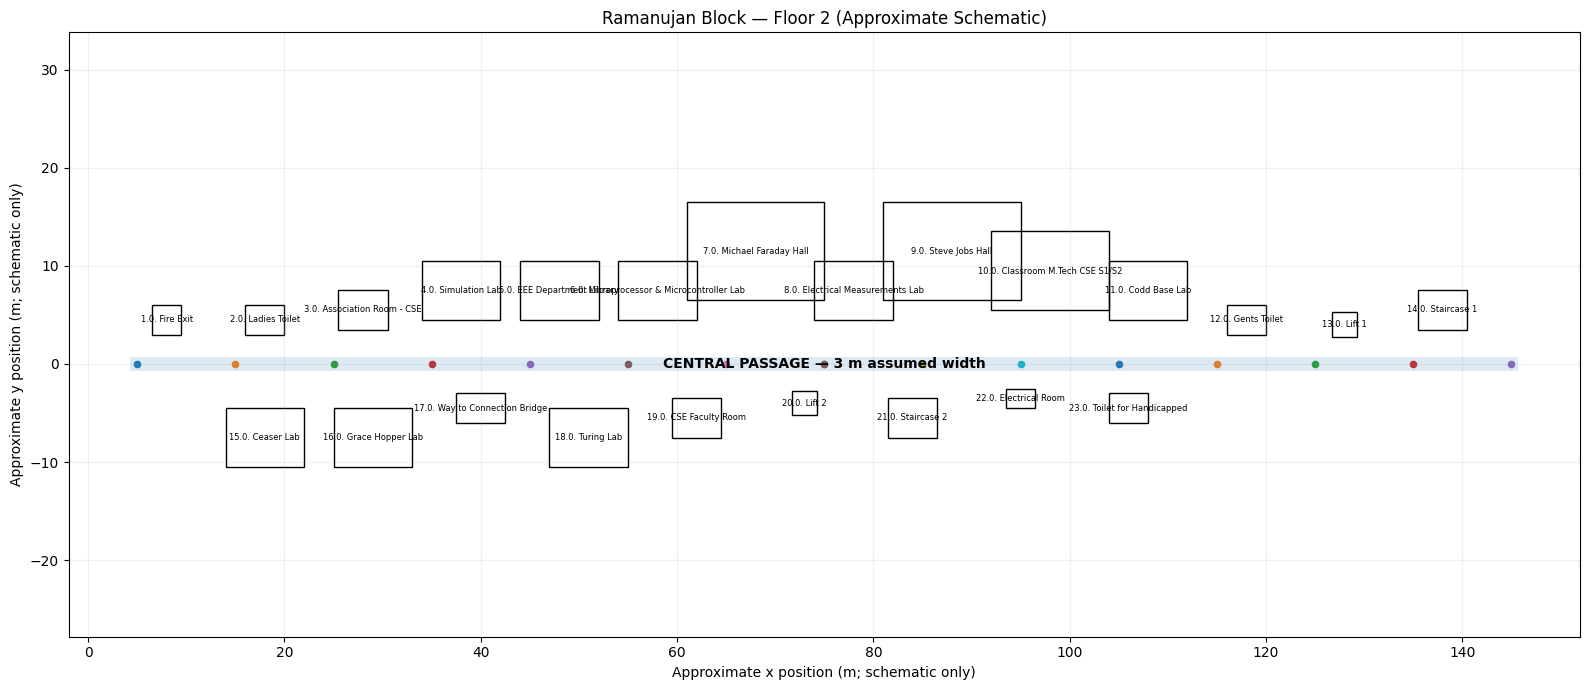

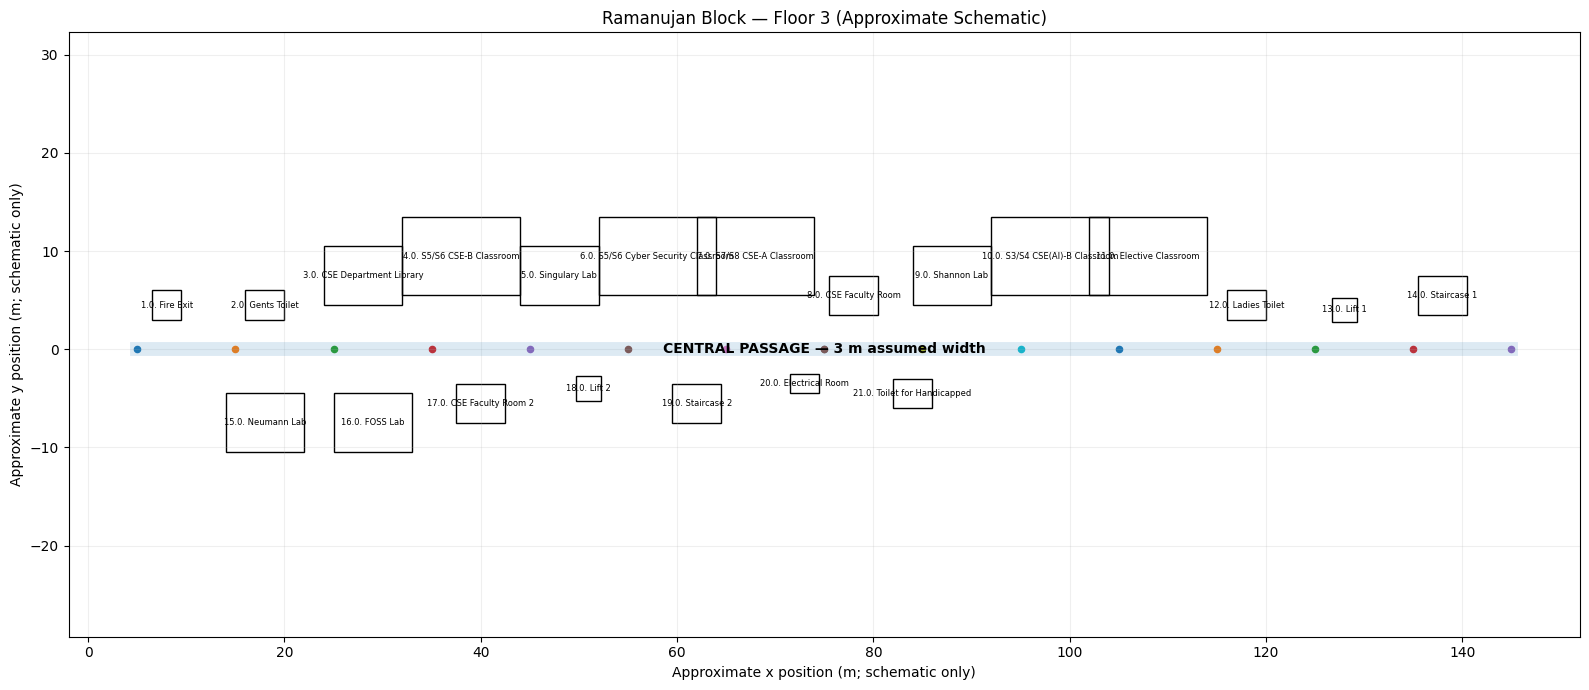

In [144]:

def plot_floor(floor_number):
    df = locations[locations["floor"] == floor_number].copy()

    fig, ax = plt.subplots(figsize=(16, 7))
    ax.set_title(
        f"Ramanujan Block — Floor {floor_number} (Approximate Schematic)"
    )

    junctions = df[
        df["type"] == "corridor_junction"
    ].sort_values("x_m")

    if len(junctions):
        ax.plot(
            junctions["x_m"],
            [0] * len(junctions),
            linewidth=10,
            alpha=0.15
        )
        ax.text(
            junctions["x_m"].mean(),
            0,
            "CENTRAL PASSAGE — 3 m assumed width",
            ha="center",
            va="center",
            fontsize=10,
            weight="bold"
        )

    for _, r in df.iterrows():
        if r["type"] in ("corridor_junction", "passage_label"):
            ax.scatter(r["x_m"], r["y_m"], s=20)
            continue

        rect_y = (
            r["y_m"]
            if r["y_m"] >= 0
            else r["y_m"] - r["height_m"]
        )

        rect = patches.Rectangle(
            (r["x_m"] - r["width_m"] / 2, rect_y),
            r["width_m"],
            r["height_m"],
            fill=False,
            linewidth=1
        )
        ax.add_patch(rect)

        ax.text(
            r["x_m"],
            rect_y + r["height_m"] / 2,
            f'{r["number"]}. {r["name"]}',
            ha="center",
            va="center",
            fontsize=6,
            wrap=True
        )

    ax.set_xlabel("Approximate x position (m; schematic only)")
    ax.set_ylabel("Approximate y position (m; schematic only)")
    ax.grid(alpha=0.2)
    ax.set_aspect("equal", adjustable="datalim")
    plt.tight_layout()
    plt.show()


plot_floor(2)
plot_floor(3)


## Cell 8 — Build the graph

The graph is undirected: walking between two connected points is allowed in either direction. Distances are used as edge costs. Closed edges are skipped.

In [145]:

graph = {node_id: [] for node_id in locations["id"]}

for _, row in connections.iterrows():
    a, b = row["from_id"], row["to_id"]
    cost = float(row["distance_m"])

    meta = {
        "edge_type": row["edge_type"],
        "accessible": bool(row["accessible"]),
        "closed": bool(row["closed"]),
        "verified": bool(row["verified"]),
        "notes": row["notes"]
    }

    graph[a].append((b, cost, meta))
    graph[b].append((a, cost, meta))

print("Graph nodes:", len(graph))
print(
    "Directed adjacency entries:",
    sum(len(v) for v in graph.values())
)


Graph nodes: 76
Directed adjacency entries: 158


## Cell 9 — Helper functions

You can enter either an exact location ID (such as `2F_04`) or a room name. The helper finds the ID from the table.

In [146]:

def find_location(query):
    query = str(query).strip().lower()

    exact_id = locations[
        locations["id"].str.lower() == query
    ]

    if not exact_id.empty:
        return exact_id.iloc[0]["id"]

    matches = locations[
        locations["name"].str.lower().str.contains(
            query, na=False
        )
    ]

    if matches.empty:
        raise ValueError(f"No location matched: {query}")

    if len(matches) > 1:
        print("Multiple matches found:")
        display(matches[["id", "floor", "name"]])
        raise ValueError(
            "Please use one of the exact IDs shown above."
        )

    return matches.iloc[0]["id"]


def get_neighbors(node, wheelchair=False):
    result = []

    for neighbor, cost, meta in graph.get(node, []):
        if meta["closed"]:
            continue

        if wheelchair and meta["accessible"] is not True:
            continue

        result.append((neighbor, cost, meta))

    return result


## Cell 10 — Breadth-First Search (BFS)

BFS finds a route with the fewest graph edges. It does **not** guarantee the shortest distance in metres.

In [147]:

def bfs(start, goal, wheelchair=False):
    queue = deque([start])
    parent = {start: None}

    while queue:
        current = queue.popleft()

        if current == goal:
            break

        for neighbor, _, _ in get_neighbors(
            current, wheelchair
        ):
            if neighbor not in parent:
                parent[neighbor] = current
                queue.append(neighbor)

    if goal not in parent:
        return None

    path = []
    node = goal

    while node is not None:
        path.append(node)
        node = parent[node]

    return path[::-1]


## Cell 11 — Depth-First Search (DFS)

DFS explores one branch deeply before backtracking. It returns a valid route when one is found, but not necessarily the shortest route.

In [148]:

def dfs(start, goal, wheelchair=False):
    stack = [start]
    parent = {start: None}

    while stack:
        current = stack.pop()

        if current == goal:
            break

        for neighbor, _, _ in reversed(
            get_neighbors(current, wheelchair)
        ):
            if neighbor not in parent:
                parent[neighbor] = current
                stack.append(neighbor)

    if goal not in parent:
        return None

    path = []
    node = goal

    while node is not None:
        path.append(node)
        node = parent[node]

    return path[::-1]


## Cell 12 — Uniform Cost Search (UCS)

UCS expands the route with the lowest accumulated edge cost. With non-negative distances, it finds a minimum-cost route in this graph.

In [149]:

def ucs(start, goal, wheelchair=False):
    pq = [(0.0, start)]
    best_cost = {start: 0.0}
    parent = {start: None}

    while pq:
        cost_so_far, current = heapq.heappop(pq)

        if cost_so_far != best_cost.get(current):
            continue

        if current == goal:
            break

        for neighbor, edge_cost, _ in get_neighbors(
            current, wheelchair
        ):
            new_cost = cost_so_far + edge_cost

            if new_cost < best_cost.get(
                neighbor, float("inf")
            ):
                best_cost[neighbor] = new_cost
                parent[neighbor] = current
                heapq.heappush(
                    pq, (new_cost, neighbor)
                )

    if goal not in parent:
        return None, float("inf")

    path = []
    node = goal

    while node is not None:
        path.append(node)
        node = parent[node]

    return path[::-1], best_cost[goal]


## Cell 13 — Heuristic and Greedy Best-First Search

We use straight-line distance between approximate coordinates as a heuristic. Since coordinates are schematic, Greedy and A* results are also prototype results. A* is only guaranteed optimal if the heuristic is admissible for the actual edge costs.

In [150]:

coord = locations.set_index("id")[
    ["x_m", "y_m"]
].to_dict("index")


def heuristic(node, goal):
    x1, y1 = coord[node]["x_m"], coord[node]["y_m"]
    x2, y2 = coord[goal]["x_m"], coord[goal]["y_m"]

    return ((x2 - x1)**2 + (y2 - y1)**2)**0.5


def greedy_best_first(start, goal, wheelchair=False):
    pq = [(heuristic(start, goal), start)]
    parent = {start: None}
    visited = set()

    while pq:
        _, current = heapq.heappop(pq)

        if current in visited:
            continue

        visited.add(current)

        if current == goal:
            break

        for neighbor, _, _ in get_neighbors(
            current, wheelchair
        ):
            if neighbor not in visited and neighbor not in parent:
                parent[neighbor] = current
                heapq.heappush(
                    pq, (heuristic(neighbor, goal), neighbor)
                )

    if goal not in parent:
        return None

    path = []
    node = goal

    while node is not None:
        path.append(node)
        node = parent[node]

    return path[::-1]


## Cell 14 — A* Search

A* ranks nodes using `g(n) + h(n)`: accumulated cost so far plus the heuristic estimate to the goal.

In [151]:

def astar(start, goal, wheelchair=False):
    pq = [(heuristic(start, goal), 0.0, start)]
    best_cost = {start: 0.0}
    parent = {start: None}

    while pq:
        _, cost_so_far, current = heapq.heappop(pq)

        if cost_so_far != best_cost.get(current):
            continue

        if current == goal:
            break

        for neighbor, edge_cost, _ in get_neighbors(
            current, wheelchair
        ):
            new_cost = cost_so_far + edge_cost

            if new_cost < best_cost.get(
                neighbor, float("inf")
            ):
                best_cost[neighbor] = new_cost
                parent[neighbor] = current

                heapq.heappush(
                    pq,
                    (
                        new_cost + heuristic(neighbor, goal),
                        new_cost,
                        neighbor
                    )
                )

    if goal not in parent:
        return None, float("inf")

    path = []
    node = goal

    while node is not None:
        path.append(node)
        node = parent[node]

    return path[::-1], best_cost[goal]


## Cell 15 — Display a route clearly

This converts node IDs to room names and sums the edge costs along a route.

In [152]:

def route_distance(path):
    if not path or len(path) < 2:
        return 0.0

    total = 0.0

    for a, b in zip(path[:-1], path[1:]):
        options = [
            cost
            for n, cost, meta in graph[a]
            if n == b and not meta["closed"]
        ]

        if not options:
            return float("inf")

        total += min(options)

    return total


def show_route(path):
    if not path:
        print("No route found.")
        return

    names = locations.set_index("id")["name"].to_dict()

    print(
        " -> ".join(
            f"{node} ({names.get(node, node)})"
            for node in path
        )
    )

    print(
        f"Estimated route cost: {route_distance(path):.1f} m"
    )


## Cell 16 — Choose start and destination

Change these values to any location IDs from the location table. The example is a route from the second-floor Simulation Lab to the third-floor Shannon Lab.

In [153]:

start = "2F_04"   # Simulation Lab
goal = "3F_09"    # Shannon Lab

print(
    "Start:",
    locations.loc[locations["id"] == start, "name"].iloc[0]
)

print(
    "Goal:",
    locations.loc[locations["id"] == goal, "name"].iloc[0]
)


Start: Simulation Lab
Goal: Shannon Lab


## Cell 17 — Run and compare all five algorithms

BFS and DFS return a path; UCS and A* also return their calculated cost. For fair comparison, this cell computes route cost for every returned path.

In [154]:

algorithms = {
    "BFS": lambda: bfs(start, goal),
    "DFS": lambda: dfs(start, goal),
    "UCS": lambda: ucs(start, goal)[0],
    "Greedy Best-First": lambda: greedy_best_first(start, goal),
    "A*": lambda: astar(start, goal)[0]
}

results = []

for name, fn in algorithms.items():
    t0 = time.perf_counter()
    path = fn()
    elapsed_ms = (time.perf_counter() - t0) * 1000

    results.append({
        "Algorithm": name,
        "Path found": path is not None,
        "Number of edges": len(path) - 1 if path else None,
        "Estimated route cost (m)": (
            round(route_distance(path), 2) if path else None
        ),
        "Runtime (ms)": round(elapsed_ms, 4),
        "Path": path
    })

comparison = pd.DataFrame(results)

display(comparison.drop(columns=["Path"]))

for row in results:
    print("\n" + row["Algorithm"])
    show_route(row["Path"])


,Algorithm,Path found,Number of edges,Estimated route cost (m),Runtime (ms)
0,BFS,True,10,95.0,0.1180
1,DFS,True,18,176.0,0.0653
2,UCS,True,10,94.5,0.1129
3,Greedy Best-First,True,10,95.0,0.0845
4,A*,True,10,94.5,0.0844



BFS
2F_04 (Simulation Lab) -> 2F_J06 (Passage Junction 6) -> 2F_J07 (Passage Junction 7) -> 2F_J08 (Passage Junction 8) -> 2F_J09 (Passage Junction 9) -> 2F_21 (Staircase 2) -> 3F_19 (Staircase 2) -> 3F_J07 (Passage Junction 7) -> 3F_J08 (Passage Junction 8) -> 3F_J09 (Passage Junction 9) -> 3F_09 (Shannon Lab)
Estimated route cost: 95.0 m

DFS
2F_04 (Simulation Lab) -> 2F_J06 (Passage Junction 6) -> 2F_J05 (Passage Junction 5) -> 2F_J04 (Passage Junction 4) -> 2F_J03 (Passage Junction 3) -> 2F_J02 (Passage Junction 2) -> 2F_J01 (Passage Junction 1) -> 2F_01 (Fire Exit) -> 3F_01 (Fire Exit) -> 3F_J01 (Passage Junction 1) -> 3F_J02 (Passage Junction 2) -> 3F_J03 (Passage Junction 3) -> 3F_J04 (Passage Junction 4) -> 3F_J05 (Passage Junction 5) -> 3F_J06 (Passage Junction 6) -> 3F_J07 (Passage Junction 7) -> 3F_J08 (Passage Junction 8) -> 3F_J09 (Passage Junction 9) -> 3F_09 (Shannon Lab)
Estimated route cost: 176.0 m

UCS
2F_04 (Simulation Lab) -> 2F_J06 (Passage Junction 6) -> 2F_J07 

## Cell 18 — Test wheelchair-friendly routing

This mode excludes connections marked inaccessible (currently assumed to be staircases). Accessibility values are provisional assumptions and must be checked against the actual building.

In [155]:

wheelchair_path, wheelchair_cost = astar(
    start, goal, wheelchair=True
)

print("Wheelchair-mode route:")
show_route(wheelchair_path)


Wheelchair-mode route:
2F_04 (Simulation Lab) -> 2F_J06 (Passage Junction 6) -> 2F_J07 (Passage Junction 7) -> 2F_J08 (Passage Junction 8) -> 2F_20 (Lift 2) -> 3F_18 (Lift 2) -> 3F_J06 (Passage Junction 6) -> 3F_J07 (Passage Junction 7) -> 3F_J08 (Passage Junction 8) -> 3F_J09 (Passage Junction 9) -> 3F_09 (Shannon Lab)
Estimated route cost: 94.5 m


## Cell 19 — Try any two locations by name or ID

Examples: `2F_07`, `3F_16`, `CSE Department Library`, `Ladies Toilet`. If a name appears more than once, use the exact ID shown.

In [156]:

start_query = "2F_04"
goal_query = "3F_09"

start_id = find_location(start_query)
goal_id = find_location(goal_query)

path, cost = astar(start_id, goal_id)

print("Start ID:", start_id)
print("Goal ID:", goal_id)

show_route(path)


Start ID: 2F_04
Goal ID: 3F_09
2F_04 (Simulation Lab) -> 2F_J06 (Passage Junction 6) -> 2F_J07 (Passage Junction 7) -> 2F_J08 (Passage Junction 8) -> 2F_20 (Lift 2) -> 3F_18 (Lift 2) -> 3F_J06 (Passage Junction 6) -> 3F_J07 (Passage Junction 7) -> 3F_J08 (Passage Junction 8) -> 3F_J09 (Passage Junction 9) -> 3F_09 (Shannon Lab)
Estimated route cost: 94.5 m


## Cell 20 — Export the generated data

This saves the tables and graph so they can be reused later. Files will appear in the Colab session's Files panel.

In [157]:
locations.to_csv("ramanujan_locations_approx.csv", index=False)
connections.to_csv("ramanujan_connections_approx.csv", index=False)

graph_json = {
    "building": "Ramanujan Block",
    "floors": [2, 3],
    "assumptions": {
        "central_passage_width_m": CORRIDOR_WIDTH_M,
        "floor_sizes": "approximately equal",
        "room_dimensions": "capacity-based assumptions",
        "coordinates_and_distances": "schematic estimates; not measured or verified"
    },
    "locations": locations.to_dict(orient="records"),
    "connections": connections.to_dict(orient="records")
}
with open("ramanujan_graph_approx.json", "w") as f:
    json.dump(graph_json, f, indent=2)

print("Saved locations CSV, connections CSV, and graph JSON.")

Saved locations CSV, connections CSV, and graph JSON.


In [158]:
# FINAL OUTPUT: Intelligent Campus Navigation Agent

start = "2F_04"   # Simulation Lab, Second Floor
goal = "3F_09"    # Shannon Lab, Third Floor

print("=" * 60)
print(" INTELLIGENT CAMPUS NAVIGATION AGENT")
print(" RAMANUJAN BLOCK - FLOORS 2 AND 3")
print("=" * 60)

start_name = locations.loc[
    locations["id"] == start, "name"
].iloc[0]

goal_name = locations.loc[
    locations["id"] == goal, "name"
].iloc[0]

print(f"\nStarting location: {start_name} (Floor 2)")
print(f"Destination:       {goal_name} (Floor 3)")

# Run all five search algorithms
results = {
    "BFS": bfs(start, goal),
    "DFS": dfs(start, goal),
    "UCS": ucs(start, goal)[0],
    "Greedy Best-First Search": greedy_best_first(start, goal),
    "A* Search": astar(start, goal)[0]
}

print("\n" + "-" * 60)
print("ROUTE COMPARISON")
print("-" * 60)

for algorithm, path in results.items():
    print(f"\n{algorithm}")

    if path:
        names = locations.set_index("id")["name"].to_dict()
        route = " -> ".join(
            f"{node} ({names.get(node, node)})"
            for node in path
        )
        print("Route:", route)
        print("Estimated cost:", round(route_distance(path), 2), "m")
        print("Number of edges:", len(path) - 1)
    else:
        print("No route found.")

print("\n" + "=" * 60)
print("NAVIGATION EXECUTION COMPLETED")
print("=" * 60)

 INTELLIGENT CAMPUS NAVIGATION AGENT
 RAMANUJAN BLOCK - FLOORS 2 AND 3

Starting location: Simulation Lab (Floor 2)
Destination:       Shannon Lab (Floor 3)

------------------------------------------------------------
ROUTE COMPARISON
------------------------------------------------------------

BFS
Route: 2F_04 (Simulation Lab) -> 2F_J06 (Passage Junction 6) -> 2F_J07 (Passage Junction 7) -> 2F_J08 (Passage Junction 8) -> 2F_J09 (Passage Junction 9) -> 2F_21 (Staircase 2) -> 3F_19 (Staircase 2) -> 3F_J07 (Passage Junction 7) -> 3F_J08 (Passage Junction 8) -> 3F_J09 (Passage Junction 9) -> 3F_09 (Shannon Lab)
Estimated cost: 95.0 m
Number of edges: 10

DFS
Route: 2F_04 (Simulation Lab) -> 2F_J06 (Passage Junction 6) -> 2F_J05 (Passage Junction 5) -> 2F_J04 (Passage Junction 4) -> 2F_J03 (Passage Junction 3) -> 2F_J02 (Passage Junction 2) -> 2F_J01 (Passage Junction 1) -> 2F_01 (Fire Exit) -> 3F_01 (Fire Exit) -> 3F_J01 (Passage Junction 1) -> 3F_J02 (Passage Junction 2) -> 3F_J03 (Pas

In [159]:

# Cell 20 — Export map data for the Streamlit app

locations.to_csv("ramanujan_locations_approx.csv", index=False)
connections.to_csv("ramanujan_connections_approx.csv", index=False)

print("Export completed!")
print("Locations:", len(locations))
print("Connections:", len(connections))
print("Download these two CSV files for the Streamlit app.")


Export completed!
Locations: 76
Connections: 79
Download these two CSV files for the Streamlit app.


In [160]:
!pip install streamlit

In [161]:
%%writefile app.py


import heapq

import time



import pandas as pd

import plotly.graph_objects as go

import streamlit as st





# ============================================================

# CampusNav AI — interactive 3D campus navigation prototype

# Reads the CSV files exported from the existing Colab notebook.

# ============================================================



st.set_page_config(

    page_title="CampusNav AI | Smart Indoor Navigation",

    page_icon="🧭",

    layout="wide",

    initial_sidebar_state="expanded",

)



st.markdown(

    """

    <style>

      @import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700&family=Space+Grotesk:wght@500;600;700&display=swap');

      html, body, [class*="css"] { font-family: 'DM Sans', sans-serif; }

      .stApp { background: linear-gradient(145deg, #07111f 0%, #0b1425 55%, #101a2e 100%); }

      h1, h2, h3 { font-family: 'Space Grotesk', sans-serif !important; }

      .hero {

        padding: 1.35rem 1.55rem; border-radius: 22px;

        background: linear-gradient(115deg, rgba(20,184,166,.20), rgba(59,130,246,.17));

        border: 1px solid rgba(148,163,184,.24); margin-bottom: 1rem;

      }

      .eyebrow { color: #5eead4; letter-spacing: .15em; font-size: .72rem; font-weight: 700; }

      .hero-title { color: #f8fafc; font-size: 2.15rem; font-weight: 700; line-height: 1.15; margin: .35rem 0; }

      .hero-sub { color: #b8c5d8; font-size: .98rem; }

      .small-note { color: #9caec4; font-size: .82rem; }

      div[data-testid="stMetric"] {

        background: rgba(15, 29, 49, .82); border: 1px solid rgba(148,163,184,.18);

        padding: 14px 16px; border-radius: 16px;

      }

      div.stButton > button[kind="primary"] {

        border: 0; border-radius: 12px; min-height: 3rem;

        background: linear-gradient(90deg, #0d9488, #2563eb);

        font-weight: 700;

      }

      div.stButton > button { border-radius: 10px; }

      section[data-testid="stSidebar"] { background: #0a1424; }

      .route-step {

        padding: .7rem .9rem; margin: .35rem 0; border-radius: 12px;

        background: rgba(15, 29, 49, .9); border: 1px solid rgba(148,163,184,.14);

      }

      .step-num { display:inline-block; min-width: 1.7rem; color:#5eead4; font-weight:700; }

      .stTabs [data-baseweb="tab-list"] { gap: 8px; }

      .stTabs [data-baseweb="tab"] { border-radius: 10px; padding: 8px 14px; }

    </style>

    """,

    unsafe_allow_html=True,

)



# ----------------------- Load data -----------------------

@st.cache_data

def load_data():

    loc = pd.read_csv("ramanujan_locations_approx.csv")

    edges = pd.read_csv("ramanujan_connections_approx.csv")

    loc["id"] = loc["id"].astype(str)

    edges["from_id"] = edges["from_id"].astype(str)

    edges["to_id"] = edges["to_id"].astype(str)

    loc["floor"] = pd.to_numeric(loc["floor"], errors="coerce").fillna(0).astype(int)

    for c in ["x_m", "y_m"]:

        loc[c] = pd.to_numeric(loc[c], errors="coerce").fillna(0.0)

    edges["distance_m"] = pd.to_numeric(edges["distance_m"], errors="coerce").fillna(1.0)

    return loc, edges



try:

    locations, connections = load_data()

except FileNotFoundError:

    st.error(

        "Map data files are missing. Upload `ramanujan_locations_approx.csv` "

        "and `ramanujan_connections_approx.csv` beside `app.py`."

    )

    st.stop()



location_ids = set(locations["id"])

names = dict(zip(locations["id"], locations["name"].fillna(locations["id"])))

floors = dict(zip(locations["id"], locations["floor"]))

coord = locations.set_index("id")[["x_m", "y_m", "floor"]].to_dict("index")



def as_bool(value):

    return str(value).strip().lower() in ("true", "1", "yes", "t")



graph = {node: [] for node in location_ids}

for _, row in connections.iterrows():

    a, b = row["from_id"], row["to_id"]

    if a not in graph or b not in graph:

        continue

    meta = {

        "edge_type": str(row.get("edge_type", "corridor")),

        "accessible": as_bool(row.get("accessible", True)),

        "closed": as_bool(row.get("closed", False)),

        "verified": as_bool(row.get("verified", False)),

    }

    cost = float(row["distance_m"])

    graph[a].append((b, cost, meta))

    graph[b].append((a, cost, meta))



def neighbors(node, wheelchair=False):

    return [

        (n, cost, meta) for n, cost, meta in graph.get(node, [])

        if not meta["closed"] and (not wheelchair or meta["accessible"])

    ]



def heuristic(a, b):

    # Floor height is visual only; the route cost still uses the notebook's edge costs.

    ca, cb = coord[a], coord[b]

    za = 3.5 * (ca["floor"] - 2)

    zb = 3.5 * (cb["floor"] - 2)

    return ((ca["x_m"] - cb["x_m"])**2 +

            (ca["y_m"] - cb["y_m"])**2 + (za-zb)**2) ** 0.5



def reconstruct(parent, goal):

    if goal not in parent:

        return None

    path, node = [], goal

    while node is not None:

        path.append(node)

        node = parent[node]

    return path[::-1]



def bfs(start, goal, wheelchair=False):

    queue, head = [start], 0

    parent = {start: None}

    while head < len(queue):

        cur = queue[head]

        head += 1

        if cur == goal:

            break

        for nxt, _, _ in neighbors(cur, wheelchair):

            if nxt not in parent:

                parent[nxt] = cur

                queue.append(nxt)

    return reconstruct(parent, goal)



def dfs(start, goal, wheelchair=False):

    stack, parent = [start], {start: None}

    while stack:

        cur = stack.pop()

        if cur == goal:

            break

        for nxt, _, _ in reversed(neighbors(cur, wheelchair)):

            if nxt not in parent:

                parent[nxt] = cur

                stack.append(nxt)

    return reconstruct(parent, goal)



def ucs(start, goal, wheelchair=False):

    pq, best, parent = [(0.0, start)], {start: 0.0}, {start: None}

    while pq:

        cost, cur = heapq.heappop(pq)

        if cost != best.get(cur):

            continue

        if cur == goal:

            break

        for nxt, edge_cost, _ in neighbors(cur, wheelchair):

            new = cost + edge_cost

            if new < best.get(nxt, float("inf")):

                best[nxt], parent[nxt] = new, cur

                heapq.heappush(pq, (new, nxt))

    return reconstruct(parent, goal)



def greedy_best_first(start, goal, wheelchair=False):

    pq, parent, visited = [(heuristic(start, goal), start)], {start: None}, set()

    while pq:

        _, cur = heapq.heappop(pq)

        if cur in visited:

            continue

        visited.add(cur)

        if cur == goal:

            break

        for nxt, _, _ in neighbors(cur, wheelchair):

            if nxt not in visited and nxt not in parent:

                parent[nxt] = cur

                heapq.heappush(pq, (heuristic(nxt, goal), nxt))

    return reconstruct(parent, goal)



def astar(start, goal, wheelchair=False):

    pq, best, parent = [(heuristic(start, goal), 0.0, start)], {start: 0.0}, {start: None}

    while pq:

        _, cost, cur = heapq.heappop(pq)

        if cost != best.get(cur):

            continue

        if cur == goal:

            break

        for nxt, edge_cost, _ in neighbors(cur, wheelchair):

            new = cost + edge_cost

            if new < best.get(nxt, float("inf")):

                best[nxt], parent[nxt] = new, cur

                heapq.heappush(pq, (new + heuristic(nxt, goal), new, nxt))

    return reconstruct(parent, goal)



ALGORITHMS = {

    "BFS": bfs,

    "DFS": dfs,

    "UCS": ucs,

    "Greedy Best-First": greedy_best_first,

    "A* Search": astar,

}



def path_cost(path, wheelchair=False):

    if not path:

        return float("inf")

    total = 0.0

    for a, b in zip(path[:-1], path[1:]):

        possible = [c for n, c, m in graph[a]

                    if n == b and not m["closed"]

                    and (not wheelchair or m["accessible"])]

        if not possible:

            return float("inf")

        total += min(possible)

    return total



def label(node):

    return f'{node} · {names.get(node, node)} · Floor {floors.get(node, "?")}'



# ----------------------- Hero -----------------------

st.markdown(

    """

    <div class="hero">

      <div class="eyebrow">SMART INDOOR WAYFINDING · AI SEARCH</div>

      <div class="hero-title">CampusNav <span style="color:#5eead4">AI</span></div>

      <div class="hero-sub">Find a route through Ramanujan Block, across floors 2 and 3.</div>

    </div>

    """,

    unsafe_allow_html=True,

)



# ----------------------- Controls -----------------------

with st.sidebar:

    st.markdown("## 🧭 Route planner")

    st.caption("Choose where to start and where to go.")

    ids = locations["id"].tolist()

    start_default = ids.index("2F_04") if "2F_04" in ids else 0

    goal_default = ids.index("3F_09") if "3F_09" in ids else min(1, len(ids)-1)

    start = st.selectbox("START", ids, index=start_default, format_func=label)

    goal = st.selectbox("DESTINATION", ids, index=goal_default, format_func=label)

    algorithm_name = st.selectbox("SEARCH ALGORITHM", list(ALGORITHMS), index=4)

    wheelchair = st.toggle("Wheelchair-friendly route", value=False)

    find_route = st.button("✦  Find best route", type="primary", use_container_width=True)

    st.markdown("---")

    st.markdown("**Map legend**")

    st.markdown("🟢 Start &nbsp;&nbsp; 🔴 Destination &nbsp;&nbsp; 🔵 Route", unsafe_allow_html=True)

    st.caption("Floor height is visualized in 3D. Coordinates and distances are schematic estimates.")



# State makes results stay visible after Streamlit reruns on any interaction.

if "last_request" not in st.session_state:

    st.session_state.last_request = None



if find_route:

    st.session_state.last_request = {

        "start": start, "goal": goal, "algorithm": algorithm_name,

        "wheelchair": wheelchair,

    }



request = st.session_state.last_request

if request:

    start_used = request["start"]

    goal_used = request["goal"]

    algorithm_used = request["algorithm"]

    wheelchair_used = request["wheelchair"]

else:

    start_used, goal_used, algorithm_used, wheelchair_used = start, goal, algorithm_name, wheelchair



if start_used == goal_used:

    active_path = [start_used]

    elapsed = 0.0

    route_was_run = bool(request)

else:

    t0 = time.perf_counter()

    active_path = ALGORITHMS[algorithm_used](start_used, goal_used, wheelchair_used) if request else None

    elapsed = (time.perf_counter() - t0) * 1000 if request else 0.0

    route_was_run = bool(request)



# ----------------------- Top metrics -----------------------

m1, m2, m3, m4 = st.columns(4)

m1.metric("Floors", "02", "Floor 2 ↔ Floor 3")

m2.metric("Mapped locations", f"{len(locations):,}")

m3.metric("Connections", f"{len(connections):,}")

m4.metric("Algorithms", "05", "BFS · DFS · UCS · Greedy · A*")



tab_map, tab_route, tab_compare, tab_data = st.tabs(

    ["🌐 3D Campus Map", "🧭 Route steps", "⚡ Algorithm lab", "🗂️ Map data"]

)



# ----------------------- Interactive floor map -----------------------

with tab_map:
    st.markdown("### Explore Ramanujan Block")

    map_left, map_right = st.columns([2, 1])
    with map_left:
        view_mode = st.radio(
            "Map view",
            ["Combined 3D", "Floor 2", "Floor 3"],
            horizontal=True,
            key="map_view_mode",
        )
    with map_right:
        show_connections = st.toggle(
            "Show all connections", value=False, key="show_all_connections"
        )
        show_room_names = st.toggle(
            "Show room names", value=False, key="show_room_names"
        )

    if view_mode == "Floor 2":
        map_locations = locations[locations["floor"] == 2].copy()
        visible_floors = [2]
    elif view_mode == "Floor 3":
        map_locations = locations[locations["floor"] == 3].copy()
        visible_floors = [3]
    else:
        map_locations = locations.copy()
        visible_floors = sorted(locations["floor"].dropna().astype(int).unique())

    visible_ids = set(map_locations["id"].astype(str))
    fig = go.Figure()
    floor_colors = {2: "#38bdf8", 3: "#a78bfa"}

    for floor in visible_floors:
        sub = map_locations[map_locations["floor"] == floor]
        if sub.empty:
            continue
        z = 3.5 * (int(floor) - 2)
        xmin, xmax = float(sub["x_m"].min()) - 5, float(sub["x_m"].max()) + 5
        ymin, ymax = float(sub["y_m"].min()) - 5, float(sub["y_m"].max()) + 5
        fig.add_trace(go.Mesh3d(
            x=[xmin, xmax, xmax, xmin],
            y=[ymin, ymin, ymax, ymax],
            z=[z, z, z, z],
            i=[0, 0], j=[1, 2], k=[2, 3],
            color=floor_colors.get(int(floor), "#64748b"),
            opacity=0.08, hoverinfo="skip", showlegend=False,
        ))
        fig.add_trace(go.Scatter3d(
            x=[xmin, xmax], y=[0, 0], z=[z, z],
            mode="lines",
            line=dict(color=floor_colors.get(int(floor), "#64748b"), width=4),
            name=f"Floor {int(floor)} passage guide",
            hoverinfo="skip",
        ))

    # Optional network overlay. It is off by default to reduce visual clutter.
    if show_connections:
        for _, row in connections.iterrows():
            a, b = str(row["from_id"]), str(row["to_id"])
            if a not in coord or b not in coord:
                continue
            ca, cb = coord[a], coord[b]
            fa, fb = int(ca["floor"]), int(cb["floor"])
            if view_mode != "Combined 3D" and (fa not in visible_floors or fb not in visible_floors):
                continue
            za, zb = 3.5 * (fa - 2), 3.5 * (fb - 2)
            vertical = fa != fb
            fig.add_trace(go.Scatter3d(
                x=[ca["x_m"], cb["x_m"]],
                y=[ca["y_m"], cb["y_m"]],
                z=[za, zb],
                mode="lines",
                line=dict(
                    color="#fbbf24" if vertical else "#53657d",
                    width=5 if vertical else 2,
                    dash="solid",
                ),
                text=[f"{a} ↔ {b}<br>{row.get('edge_type', 'connection')}"],
                hoverinfo="text",
                showlegend=False,
            ))

    if active_path and (view_mode == "Combined 3D" or all(n in visible_ids for n in active_path)):
        route_x, route_y, route_z = [], [], []
        for node in active_path:
            c = coord[node]
            route_x.append(float(c["x_m"]))
            route_y.append(float(c["y_m"]))
            route_z.append(3.5 * (int(c["floor"]) - 2))
        fig.add_trace(go.Scatter3d(
            x=route_x, y=route_y, z=route_z,
            mode="lines+markers",
            line=dict(color="#22d3ee", width=8),
            marker=dict(size=5, color="#22d3ee",
                        line=dict(color="#ecfeff", width=1)),
            name="Selected route",
            text=[label(n) for n in active_path],
            hoverinfo="text",
        ))
    elif active_path and view_mode != "Combined 3D":
        st.info("The selected route crosses floors. Switch to Combined 3D to see the complete route.")

    palette = {
        "corridor_junction": "#64748b",
        "passage_label": "#14b8a6",
        "classroom": "#60a5fa",
        "lab": "#f59e0b",
        "lift": "#34d399",
        "stairs": "#fb7185",
    }

    for typ in map_locations["type"].fillna("room").unique():
        sub = map_locations[map_locations["type"].fillna("room") == typ]
        xs, ys, zs, hover, texts, colors, sizes = [], [], [], [], [], [], []
        for _, r in sub.iterrows():
            node = str(r["id"])
            floor = int(r["floor"])
            xs.append(float(r["x_m"]))
            ys.append(float(r["y_m"]))
            zs.append(3.5 * (floor - 2))
            hover.append(
                f"<b>{node}</b><br>{r['name']}<br>Floor {floor}"
                f"<br>Type: {typ}"
            )
            number = node.split("_")[-1] if "_" in node else node
            if show_room_names:
                texts.append(f"{number} · {r['name']}")
            else:
                texts.append(number if typ not in ("corridor_junction", "passage_label") else "")
            colors.append(palette.get(str(typ).lower(), "#cbd5e1"))
            sizes.append(7 if typ in ("corridor_junction", "passage_label") else 9)

        fig.add_trace(go.Scatter3d(
            x=xs, y=ys, z=zs,
            mode="markers+text",
            text=texts,
            textposition="top center",
            textfont=dict(size=12, color="#f8fafc"),
            marker=dict(
                size=sizes, color=colors, opacity=1,
                line=dict(color="#f8fafc", width=1.5),
            ),
            hovertext=hover,
            hoverinfo="text",
            name=str(typ).replace("_", " ").title(),
        ))

    for node, color, title in [
        (start_used, "#22c55e", "START"),
        (goal_used, "#ef4444", "DESTINATION"),
    ]:
        if node not in visible_ids:
            continue
        c = coord[node]
        fig.add_trace(go.Scatter3d(
            x=[c["x_m"]], y=[c["y_m"]],
            z=[3.5 * (int(c["floor"]) - 2)],
            mode="markers+text",
            text=[title],
            textposition="top center",
            textfont=dict(size=13, color="#ffffff"),
            marker=dict(size=11, color=color, symbol="diamond",
                        line=dict(color="#ffffff", width=2)),
            name=title,
            hovertext=[label(node)],
            hoverinfo="text",
        ))

    if view_mode == "Combined 3D":
        camera = dict(eye=dict(x=1.55, y=1.55, z=1.15))
        zaxis = dict(
            title="Floor",
            tickvals=[0, 3.5],
            ticktext=["Floor 2", "Floor 3"],
            backgroundcolor="rgba(0,0,0,0)",
            gridcolor="#25344a",
            range=[-1, 5.5],
        )
        aspectmode = "manual"
        aspectratio = dict(x=1.5, y=1.0, z=0.6)
    else:
        camera = dict(eye=dict(x=0.01, y=0.01, z=2.7))
        zaxis = dict(
            title="",
            tickvals=[3.5 * (visible_floors[0] - 2)],
            ticktext=[f"Floor {visible_floors[0]}"],
            range=[-1, 5.5],
            backgroundcolor="rgba(0,0,0,0)",
            gridcolor="#25344a",
        )
        aspectmode = "data"
        aspectratio = None

    scene_settings = dict(
        bgcolor="rgba(0,0,0,0)",
        xaxis=dict(title="Schematic X", backgroundcolor="rgba(0,0,0,0)",
                   gridcolor="#25344a", zerolinecolor="#25344a"),
        yaxis=dict(title="Schematic Y", backgroundcolor="rgba(0,0,0,0)",
                   gridcolor="#25344a", zerolinecolor="#25344a"),
        zaxis=zaxis,
        camera=camera,
        aspectmode=aspectmode,
    )
    if aspectratio is not None:
        scene_settings["aspectratio"] = aspectratio

    fig.update_layout(
        height=720,
        margin=dict(l=0, r=0, t=10, b=0),
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        font=dict(color="#dbeafe"),
        legend=dict(
            orientation="h", yanchor="bottom", y=0.01,
            xanchor="left", x=0.01, bgcolor="rgba(7,17,31,.65)",
        ),
        scene=scene_settings,
    )
    st.plotly_chart(
        fig, use_container_width=True,
        config={"displaylogo": False, "scrollZoom": True},
    )
    st.markdown(
        '<div class="small-note">Room numbers are shown on the map; hover to read full names. '
        'Connections are hidden by default to reduce clutter. Coordinates and distances remain '
        'schematic estimates; verify the graph against the floor plan before treating routes as real.</div>',
        unsafe_allow_html=True,
    )


# ----------------------- Route steps -----------------------

with tab_route:

    st.markdown("### Your navigation instructions")

    if not route_was_run:

        st.info("Choose your start, destination and algorithm in the sidebar, then click **Find best route**.")

    elif not active_path:

        st.error("No route found. Check that the floor-to-floor links exist and the accessibility settings allow a path.")

    else:

        total = path_cost(active_path, wheelchair_used)

        c1, c2, c3 = st.columns(3)

        c1.metric("Route nodes", len(active_path))

        c2.metric("Estimated cost", f"{total:.1f} units")

        c3.metric("Search runtime", f"{elapsed:.3f} ms")

        for i, node in enumerate(active_path):

            if i == 0:

                icon = "🟢"

                role = "START"

            elif i == len(active_path) - 1:

                icon = "🏁"

                role = "DESTINATION"

            else:

                icon = "↳"

                role = f"STEP {i}"

            st.markdown(

                f'<div class="route-step"><span class="step-num">{i+1:02}</span> '

                f'{icon} <b>{role}</b> &nbsp; {names.get(node, node)} '

                f'<span style="color:#94a3b8">({node} · Floor {floors[node]})</span></div>',

                unsafe_allow_html=True,

            )



# ----------------------- Responsive algorithm comparison -----------------------

with tab_compare:

    st.markdown("### Compare the five search algorithms")

    st.caption("Press the button once. Results remain visible when you switch tabs or adjust the view.")

    if st.button("▶ Run all five algorithms", type="primary", key="compare_button"):

        compare_rows = []

        compare_paths = {}

        for name, fn in ALGORITHMS.items():

            t0 = time.perf_counter()

            path = fn(start_used, goal_used, wheelchair_used)

            runtime = (time.perf_counter() - t0) * 1000

            compare_paths[name] = path

            compare_rows.append({

                "Algorithm": name,

                "Route found": "Yes" if path else "No",

                "Nodes": len(path) if path else None,

                "Edges": len(path) - 1 if path else None,

                "Estimated cost": round(path_cost(path, wheelchair_used), 2) if path else None,

                "Runtime (ms)": round(runtime, 4),

            })

        st.session_state.compare_rows = compare_rows

        st.session_state.compare_paths = compare_paths



    if "compare_rows" in st.session_state:

        comp = pd.DataFrame(st.session_state.compare_rows)

        finite = comp[comp["Estimated cost"].notna()]

        if not finite.empty:

            best_idx = finite["Estimated cost"].astype(float).idxmin()

            best_name = comp.loc[best_idx, "Algorithm"]

            st.success(f"Lowest estimated route cost in this run: **{best_name}**")

        st.dataframe(

            comp,

            use_container_width=True,

            hide_index=True,

            column_config={

                "Estimated cost": st.column_config.NumberColumn(format="%.2f"),

                "Runtime (ms)": st.column_config.NumberColumn(format="%.4f ms"),

            },

        )

        with st.expander("View the route found by each algorithm"):

            for name, path in st.session_state.compare_paths.items():

                st.markdown(f"**{name}**")

                if path:

                    st.write(" → ".join(f"{n} ({names.get(n, n)})" for n in path))

                else:

                    st.write("No route found.")

    else:

        st.info("Comparison has not been run yet. Click the button above to calculate the results.")



# ----------------------- Data overview -----------------------

with tab_data:

    st.markdown("### Locations")

    st.dataframe(

        locations[["id", "name", "floor", "type", "x_m", "y_m"]],

        use_container_width=True, hide_index=True

    )

    st.markdown("### Connections")

    st.dataframe(

        connections[["from_id", "to_id", "distance_m", "edge_type", "accessible", "verified"]],

        use_container_width=True, hide_index=True

    )



st.markdown("---")

st.markdown(

    '<div class="small-note">CampusNav AI · Intelligent Campus Navigation prototype · '

    'Search costs and geometry are approximate until the floor plan is verified.</div>',

    unsafe_allow_html=True,

)


Overwriting app.py


In [162]:
import os

print("Current folder:", os.getcwd())
print("app.py exists:", os.path.exists("app.py"))
print("Locations CSV exists:",
      os.path.exists("ramanujan_locations_approx.csv"))
print("Connections CSV exists:",
      os.path.exists("ramanujan_connections_approx.csv"))

Current folder: /content
app.py exists: True
Locations CSV exists: True
Connections CSV exists: True


In [163]:
!pip install -U pyngrok

In [164]:

!pip -q install streamlit pyngrok


In [165]:
!nohup streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1 &

In [166]:
import requests
import time

time.sleep(2)

try:
    r = requests.get("http://127.0.0.1:8501", timeout=5)
    print("Streamlit is running! Status:", r.status_code)
except Exception as e:
    print("Streamlit is NOT running.")
    print(open("streamlit.log").read())

Streamlit is running! Status: 200


In [167]:

import os
from getpass import getpass

token = getpass("Paste your ngrok authtoken: ").strip()

os.environ["NGROK_AUTHTOKEN"] = token

print("Token received:", bool(token))


Paste your ngrok authtoken: ··········
Token received: True


In [168]:
from pyngrok import ngrok

ngrok.kill()

tunnel = ngrok.connect(8501)

print("🚀 YOUR CAMPUS NAVIGATION APP:")
print(tunnel.public_url)

🚀 YOUR CAMPUS NAVIGATION APP:
https://refrain-stowing-dairy.ngrok-free.dev


In [169]:

!nohup streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1 &


In [170]:

import time
import requests

time.sleep(5)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=5)
    print("Streamlit is running! Status:", response.status_code)
except Exception as e:
    print("Streamlit did not start. Check the log below.")
    print(open("streamlit.log").read())


Streamlit is running! Status: 200


In [171]:
from pyngrok import ngrok

ngrok.kill()

tunnel = ngrok.connect(8501)

print("🚀 YOUR CAMPUS NAVIGATION APP:")
print(tunnel.public_url)

🚀 YOUR CAMPUS NAVIGATION APP:
https://refrain-stowing-dairy.ngrok-free.dev


## Performance Evaluation and Result Analysis

This section evaluates BFS, DFS, UCS, Greedy Best-First Search, and A* Search using repeated execution-time measurements, estimated route costs, and route lengths. It also checks whether the A* heuristic is admissible for the current campus graph. Since the campus coordinates and edge costs are approximate, the results represent a navigation prototype rather than a verified real-world navigation system.

In [172]:
print("Graph type:", type(graph))

first_node = next(iter(graph))
print("First graph key:", repr(first_node))
print("First graph key type:", type(first_node))
print("Connections:", repr(graph[first_node])[:1000])

print("\nBFS test:")
test_path = bfs("2F_04", "3F_09", False)
print("Path:", repr(test_path))
print("Path type:", type(test_path))

if test_path:
    print("First path item:", repr(test_path[0]))
    print("First path item type:", type(test_path[0]))

Graph type: <class 'dict'>
First graph key: '2F_01'
First graph key type: <class 'str'>
Connections: [('2F_J01', 6.0, {'edge_type': 'room_access', 'accessible': True, 'closed': False, 'verified': False, 'notes': 'Estimated connection; entrance location unverified'}), ('3F_01', 5.0, {'edge_type': 'fire_exit_stairs', 'accessible': False, 'closed': False, 'verified': False, 'notes': 'Provisional direct connection between Floor 2 and Floor 3 fire exits; replace 5.0 m with a measured distance and verify against the actual building/fire-safety plan.'})]

BFS test:
Path: ['2F_04', '2F_J06', '2F_J07', '2F_J08', '2F_J09', '2F_21', '3F_19', '3F_J07', '3F_J08', '3F_J09', '3F_09']
Path type: <class 'list'>
First path item: '2F_04'
First path item type: <class 'str'>


In [173]:
def calculate_route_cost(path, wheelchair=False):
    if not path:
        return float("inf")

    total = 0.0

    for current, next_node in zip(path[:-1], path[1:]):
        edge_cost = None

        for neighbor, cost, metadata in graph[current]:
            if neighbor != next_node:
                continue

            if metadata.get("closed", False):
                continue

            if wheelchair and not metadata.get("accessible", True):
                continue

            edge_cost = float(cost)
            break

        if edge_cost is None:
            return float("inf")

        total += edge_cost

    return total


print("Route-cost function is ready!")

# Test it with your existing BFS route
test_path = bfs("2F_04", "3F_09", False)
print("Test route:", " -> ".join(test_path))
print("Estimated route cost:", calculate_route_cost(test_path))

Route-cost function is ready!
Test route: 2F_04 -> 2F_J06 -> 2F_J07 -> 2F_J08 -> 2F_J09 -> 2F_21 -> 3F_19 -> 3F_J07 -> 3F_J08 -> 3F_J09 -> 3F_09
Estimated route cost: 95.0


In [174]:
test_path = bfs("2F_04", "3F_09", False)

print("Path:", test_path)
print("First current node:", repr(test_path[0]))
print("Type:", type(test_path[0]))

current = test_path[0]
print("Is current a graph key?", current in graph)
print("Connections for current:", repr(graph[current])[:1000])

Path: ['2F_04', '2F_J06', '2F_J07', '2F_J08', '2F_J09', '2F_21', '3F_19', '3F_J07', '3F_J08', '3F_J09', '3F_09']
First current node: '2F_04'
Type: <class 'str'>
Is current a graph key? True
Connections for current: [('2F_J06', 21.5, {'edge_type': 'room_access', 'accessible': True, 'closed': False, 'verified': False, 'notes': 'Estimated connection; entrance location unverified'})]


In [175]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

algorithms_to_test = {
    "BFS": bfs,
    "DFS": dfs,
    "UCS": ucs,
    "Greedy Best-First": greedy_best_first,
    "A* Search": astar
}

start_node = "2F_04"
goal_node = "3F_09"
REPEATS = 200

results_rows = []

for name, algorithm in algorithms_to_test.items():

    # Warm-up
    for _ in range(5):
        algorithm(start_node, goal_node, False)

    runtimes = []
    last_result = None

    # Measure execution time only; don't inspect graph connections
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        last_result = algorithm(start_node, goal_node, False)
        runtimes.append((time.perf_counter() - t0) * 1000)

    results_rows.append({
        "Algorithm": name,
        "Returned Type": type(last_result).__name__,
        "Returned Length": (
            len(last_result)
            if last_result is not None
            and hasattr(last_result, "__len__")
            else None
        ),
        "Mean Runtime (ms)": sum(runtimes) / len(runtimes),
        "Median Runtime (ms)": pd.Series(runtimes).median(),
        "Runtime Std Dev (ms)": pd.Series(runtimes).std()
    })

performance_df = pd.DataFrame(results_rows)

print("PERFORMANCE EVALUATION")
print("Start: 2F_04 — Simulation Lab")
print("Goal: 3F_09 — Shannon Lab")
print("Runs per algorithm:", REPEATS)

display(performance_df.round(6))

PERFORMANCE EVALUATION
Start: 2F_04 — Simulation Lab
Goal: 3F_09 — Shannon Lab
Runs per algorithm: 200


,Algorithm,Returned Type,Returned Length,Mean Runtime (ms),Median Runtime (ms),Runtime Std Dev (ms)
0,BFS,list,11,0.359886,0.079378,1.295347
1,DFS,list,19,0.249591,0.076267,0.843364
2,UCS,tuple,2,0.408406,0.146723,0.923587
3,Greedy Best-First,list,11,0.263077,0.088994,0.856464
4,A* Search,tuple,2,0.371576,0.121097,1.057340


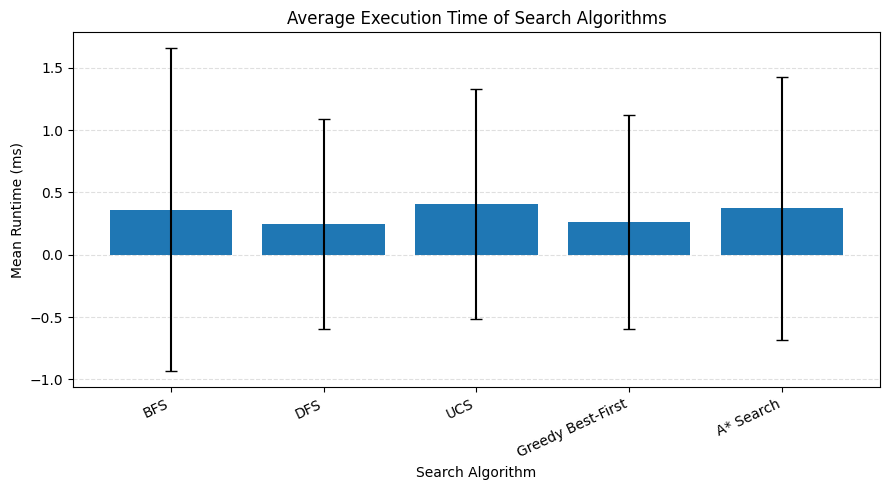

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [176]:
import matplotlib.pyplot as plt
from google.colab import files

plt.figure(figsize=(9, 5))

plt.bar(
    performance_df["Algorithm"],
    performance_df["Mean Runtime (ms)"],
    yerr=performance_df["Runtime Std Dev (ms)"],
    capsize=4
)

plt.title("Average Execution Time of Search Algorithms")
plt.xlabel("Search Algorithm")
plt.ylabel("Mean Runtime (ms)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig("average_execution_time.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("average_execution_time.png")

In [177]:
algorithms_to_test = {
    "BFS": bfs,
    "DFS": dfs,
    "UCS": ucs,
    "Greedy Best-First": greedy_best_first,
    "A* Search": astar
}

for name, algorithm in algorithms_to_test.items():
    result = algorithm("2F_04", "3F_09", False)

    print(f"\n{name}")
    print("Return type:", type(result))
    print("Returned path:", repr(result))


BFS
Return type: <class 'list'>
Returned path: ['2F_04', '2F_J06', '2F_J07', '2F_J08', '2F_J09', '2F_21', '3F_19', '3F_J07', '3F_J08', '3F_J09', '3F_09']

DFS
Return type: <class 'list'>
Returned path: ['2F_04', '2F_J06', '2F_J05', '2F_J04', '2F_J03', '2F_J02', '2F_J01', '2F_01', '3F_01', '3F_J01', '3F_J02', '3F_J03', '3F_J04', '3F_J05', '3F_J06', '3F_J07', '3F_J08', '3F_J09', '3F_09']

UCS
Return type: <class 'tuple'>
Returned path: (['2F_04', '2F_J06', '2F_J07', '2F_J08', '2F_20', '3F_18', '3F_J06', '3F_J07', '3F_J08', '3F_J09', '3F_09'], 94.5)

Greedy Best-First
Return type: <class 'list'>
Returned path: ['2F_04', '2F_J06', '2F_J07', '2F_J08', '2F_J09', '2F_21', '3F_19', '3F_J07', '3F_J08', '3F_J09', '3F_09']

A* Search
Return type: <class 'tuple'>
Returned path: (['2F_04', '2F_J06', '2F_J07', '2F_J08', '2F_20', '3F_18', '3F_J06', '3F_J07', '3F_J08', '3F_J09', '3F_09'], 94.5)


## Route Cost and Path Length Analysis

This section compares the estimated route cost and the number of edges generated by BFS, DFS, UCS, Greedy Best-First Search, and A* Search. The comparison helps evaluate route quality in addition to execution time.

In [178]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

start_node = "2F_04"
goal_node = "3F_09"

def get_path(result):
    # UCS and A* may return (path, cost)
    if isinstance(result, tuple):
        return result[0]
    return result

algorithms = {
    "BFS": lambda: bfs(start_node, goal_node),
    "DFS": lambda: dfs(start_node, goal_node),
    "UCS": lambda: ucs(start_node, goal_node),
    "Greedy Best-First": lambda: greedy_best_first(start_node, goal_node),
    "A* Search": lambda: astar(start_node, goal_node)
}

route_rows = []

for name, run_search in algorithms.items():
    result = run_search()
    path = get_path(result)

    found = path is not None and len(path) > 0

    route_rows.append({
        "Algorithm": name,
        "Route Found": found,
        "Number of Edges": len(path) - 1 if found else None,
        "Estimated Route Cost": (
            route_distance(path) if found else None
        )
    })

route_df = pd.DataFrame(route_rows)

display(route_df.round(4))

,Algorithm,Route Found,Number of Edges,Estimated Route Cost
0,BFS,True,10,95.0
1,DFS,True,18,176.0
2,UCS,True,10,94.5
3,Greedy Best-First,True,10,95.0
4,A* Search,True,10,94.5


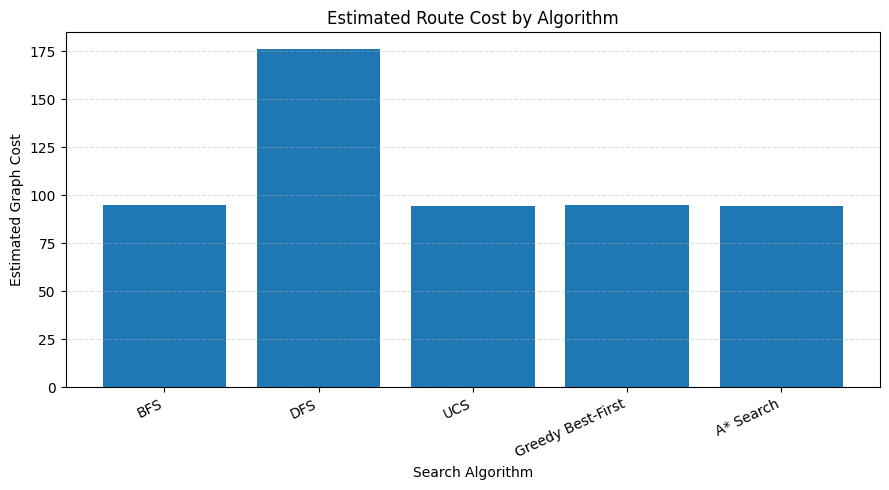

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [179]:

import matplotlib.pyplot as plt
from google.colab import files

plt.figure(figsize=(9, 5))

plt.bar(route_df["Algorithm"], route_df["Estimated Route Cost"])

plt.title("Estimated Route Cost by Algorithm")
plt.xlabel("Search Algorithm")
plt.ylabel("Estimated Graph Cost")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save and download
plt.savefig("route_cost_by_algorithm.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("route_cost_by_algorithm.png")


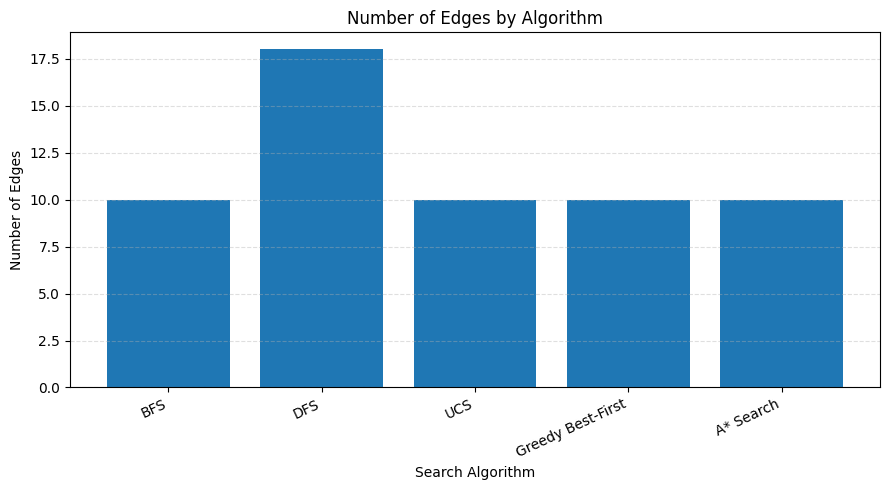

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [180]:

import matplotlib.pyplot as plt
from google.colab import files

plt.figure(figsize=(9, 5))

plt.bar(route_df["Algorithm"], route_df["Number of Edges"])

plt.title("Number of Edges by Algorithm")
plt.xlabel("Search Algorithm")
plt.ylabel("Number of Edges")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save and download
plt.savefig("number_of_edges_by_algorithm.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("number_of_edges_by_algorithm.png")


In [181]:
import heapq
import pandas as pd
from IPython.display import display

goal_node = "3F_09"

def shortest_cost_to_goal(start, goal):
    pq = [(0, start)]
    best_cost = {start: 0}

    while pq:
        cost, current = heapq.heappop(pq)

        if cost != best_cost[current]:
            continue

        if current == goal:
            return cost

        for neighbor, edge_cost, meta in get_neighbors(current, False):
            new_cost = cost + edge_cost

            if new_cost < best_cost.get(neighbor, float("inf")):
                best_cost[neighbor] = new_cost
                heapq.heappush(pq, (new_cost, neighbor))

    return float("inf")


heuristic_rows = []

for node in graph:
    actual_cost = shortest_cost_to_goal(node, goal_node)
    estimated_cost = heuristic(node, goal_node)

    if actual_cost != float("inf"):
        heuristic_rows.append({
            "Node": node,
            "Heuristic Estimate": estimated_cost,
            "Actual Shortest Cost": actual_cost,
            "Overestimates": estimated_cost > actual_cost + 1e-9
        })

heuristic_df = pd.DataFrame(heuristic_rows)
display(heuristic_df.round(3))

print("Nodes checked:", len(heuristic_df))
print("Overestimates found:", heuristic_df["Overestimates"].sum())

if heuristic_df["Overestimates"].any():
    print("The heuristic is NOT admissible for this goal.")
else:
    print("The heuristic is admissible for this goal on the current graph.")

,Node,Heuristic Estimate,Actual Shortest Cost,Overestimates
0,2F_01,80.014,98.5,False
1,2F_02,70.016,119.0,False
2,2F_03,60.008,109.5,False
3,2F_04,50.000,94.5,False
4,2F_05,40.000,84.5,False
...,...,...,...,...
71,3F_J12,27.372,37.5,False
72,3F_J13,37.273,47.5,False
73,3F_J14,47.215,57.5,False
74,3F_J15,57.177,67.5,False


Nodes checked: 76
Overestimates found: 0
The heuristic is admissible for this goal on the current graph.


### Testing Multiple Routes

The five search algorithms are tested on different start and destination pairs. Their route costs and path lengths are compared to understand how their performance changes depending on the selected locations.

In [182]:
import pandas as pd
from IPython.display import display

test_routes = [
    ("2F_04", "3F_09"),
    ("2F_07", "3F_08")
]

algorithms = {
    "BFS": bfs,
    "DFS": dfs,
    "UCS": ucs,
    "Greedy Best-First": greedy_best_first,
    "A* Search": astar
}

rows = []

for start_node, goal_node in test_routes:
    for name, algorithm in algorithms.items():
        result = algorithm(start_node, goal_node, False)

        # Some versions of UCS and A* return (path, cost)
        path = result[0] if isinstance(result, tuple) else result

        found = path is not None and len(path) > 0

        rows.append({
            "Start": start_node,
            "Destination": goal_node,
            "Algorithm": name,
            "Route Found": found,
            "Number of Edges": len(path) - 1 if found else None,
            "Estimated Route Cost": (
                route_distance(path) if found else None
            )
        })

multi_route_df = pd.DataFrame(rows)

display(multi_route_df.round(2))

,Start,Destination,Algorithm,Route Found,Number of Edges,Estimated Route Cost
0,2F_04,3F_09,BFS,True,10,95.0
1,2F_04,3F_09,DFS,True,18,176.0
2,2F_04,3F_09,UCS,True,10,94.5
3,2F_04,3F_09,Greedy Best-First,True,10,95.0
4,2F_04,3F_09,A* Search,True,10,94.5
5,2F_07,3F_08,BFS,True,8,62.0
6,2F_07,3F_08,DFS,True,18,163.0
7,2F_07,3F_08,UCS,True,8,61.5
8,2F_07,3F_08,Greedy Best-First,True,8,62.0
9,2F_07,3F_08,A* Search,True,8,61.5


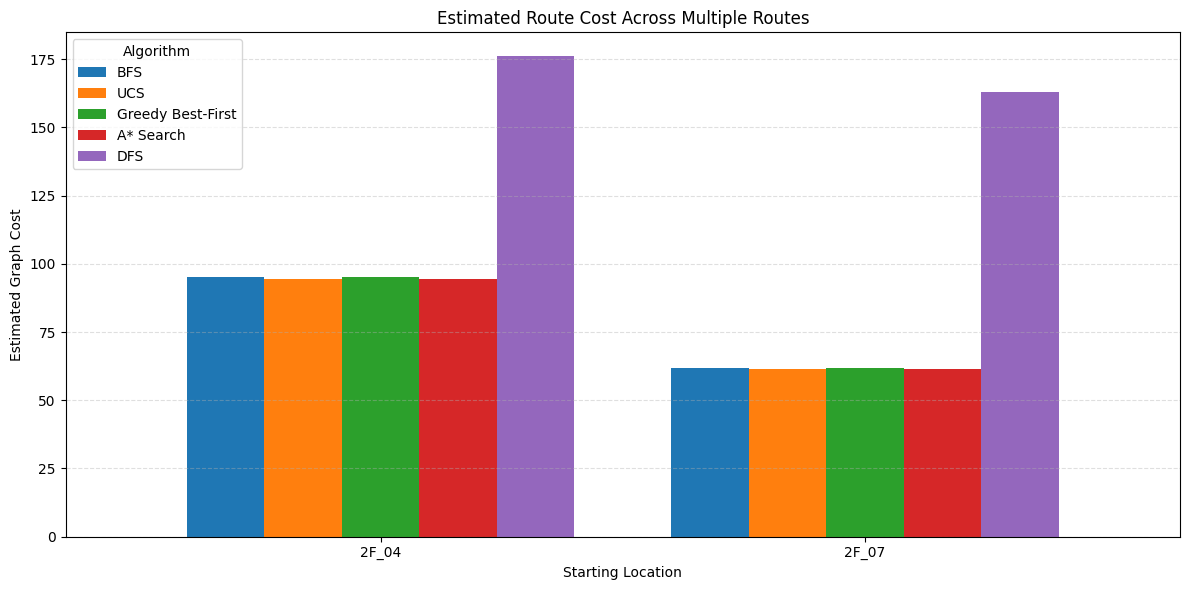

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [183]:

import matplotlib.pyplot as plt
from google.colab import files

# Recreate the table from your multi-route results
cost_pivot = multi_route_df.pivot(
    index="Start",
    columns="Algorithm",
    values="Estimated Route Cost"
)

# Move DFS to the last position
algorithm_order = [
    "BFS",
    "UCS",
    "Greedy Best-First",
    "A* Search",
    "DFS"
]

# Create the graph
ax = cost_pivot[algorithm_order].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Estimated Route Cost Across Multiple Routes")
plt.xlabel("Starting Location")
plt.ylabel("Estimated Graph Cost")
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the graph in high resolution
plt.savefig(
    "multiple_route_cost.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the graph
plt.show()

# Download the image
files.download("multiple_route_cost.png")


In [184]:
average_performance = (
    multi_route_df
    .groupby("Algorithm")
    .agg(
        Average_Route_Cost=("Estimated Route Cost", "mean"),
        Average_Number_of_Edges=("Number of Edges", "mean"),
        Routes_Found=("Route Found", "sum")
    )
    .reset_index()
)

display(average_performance.round(2))

,Algorithm,Average_Route_Cost,Average_Number_of_Edges,Routes_Found
0,A* Search,78.0,9.0,2
1,BFS,78.5,9.0,2
2,DFS,169.5,18.0,2
3,Greedy Best-First,78.5,9.0,2
4,UCS,78.0,9.0,2


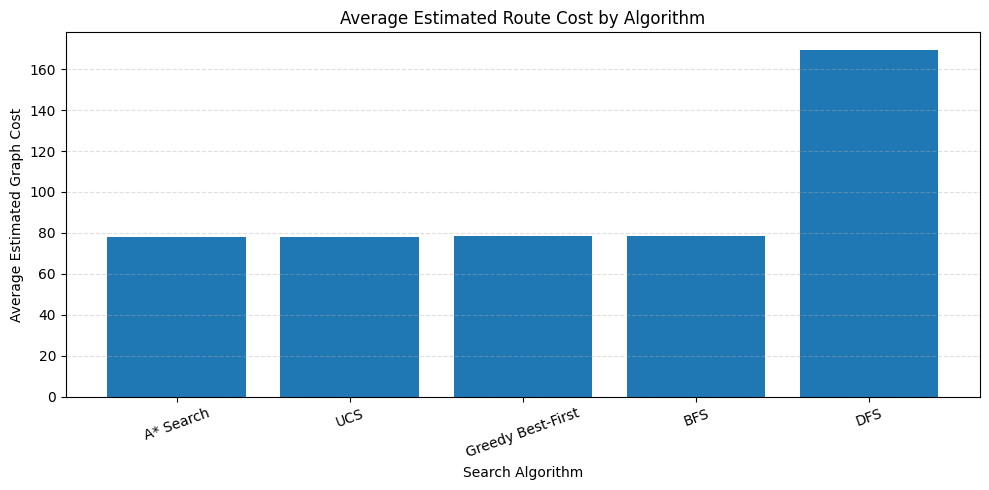

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [185]:
import matplotlib.pyplot as plt
from google.colab import files

average_plot = average_performance.sort_values(
    "Average_Route_Cost"
)

plt.figure(figsize=(10, 5))

plt.bar(
    average_plot["Algorithm"],
    average_plot["Average_Route_Cost"]
)

plt.title("Average Estimated Route Cost by Algorithm")
plt.xlabel("Search Algorithm")
plt.ylabel("Average Estimated Graph Cost")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the graph as a high-quality image
plt.savefig("average_route_cost.png", dpi=300, bbox_inches="tight")

plt.show()

# Download the image to your computer
files.download("average_route_cost.png")

In [186]:
wheelchair_rows = []

start_node = "2F_04"
goal_node = "3F_09"

for name, algorithm in algorithms.items():
    result = algorithm(start_node, goal_node, True)

    path = result[0] if isinstance(result, tuple) else result
    found = path is not None and len(path) > 0

    wheelchair_rows.append({
        "Algorithm": name,
        "Route Found": found,
        "Number of Edges": len(path) - 1 if found else None,
        "Estimated Route Cost": (
            route_distance(path) if found else None
        )
    })

wheelchair_df = pd.DataFrame(wheelchair_rows)
display(wheelchair_df.round(2))

,Algorithm,Route Found,Number of Edges,Estimated Route Cost
0,BFS,True,10,94.5
1,DFS,True,16,154.5
2,UCS,True,10,94.5
3,Greedy Best-First,True,10,94.5
4,A* Search,True,10,94.5


In [187]:
comparison_df = multi_route_df[
    (multi_route_df["Start"] == start_node) &
    (multi_route_df["Destination"] == goal_node)
][["Algorithm", "Estimated Route Cost"]].merge(
    wheelchair_df[["Algorithm", "Estimated Route Cost"]],
    on="Algorithm",
    suffixes=("_Normal", "_Wheelchair")
)

display(comparison_df.round(2))

,Algorithm,Estimated Route Cost_Normal,Estimated Route Cost_Wheelchair
0,BFS,95.0,94.5
1,DFS,176.0,154.5
2,UCS,94.5,94.5
3,Greedy Best-First,95.0,94.5
4,A* Search,94.5,94.5


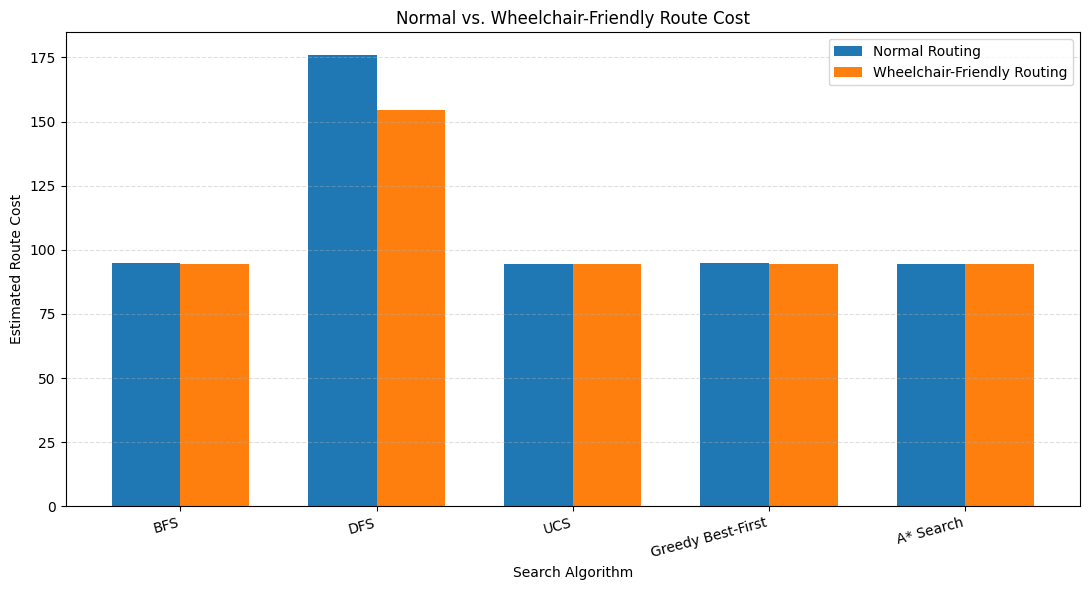

In [188]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Route costs obtained from the experiment
comparison_df = pd.DataFrame({
    "Algorithm": [
        "BFS",
        "DFS",
        "UCS",
        "Greedy Best-First",
        "A* Search"
    ],
    "Normal Route Cost": [95.0, 176.0, 94.5, 95.0, 94.5],
    "Wheelchair Route Cost": [94.5, 154.5, 94.5, 94.5, 94.5]
})

# Set positions for the bars
x = np.arange(len(comparison_df))
width = 0.35

# Create the graph
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    comparison_df["Normal Route Cost"],
    width,
    label="Normal Routing"
)

ax.bar(
    x + width / 2,
    comparison_df["Wheelchair Route Cost"],
    width,
    label="Wheelchair-Friendly Routing"
)

# Add labels and formatting
ax.set_xlabel("Search Algorithm")
ax.set_ylabel("Estimated Route Cost")
ax.set_title("Normal vs. Wheelchair-Friendly Route Cost")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Algorithm"], rotation=15, ha="right")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


In [189]:
# Select a connection from the original route
start_node = "2F_04"
goal_node = "3F_09"

original_path = astar(start_node, goal_node, False)
original_path = (
    original_path[0]
    if isinstance(original_path, tuple)
    else original_path
)

if original_path and len(original_path) >= 2:
    blocked_a = original_path[0]
    blocked_b = original_path[1]

    # Save the original graph before modifying it
    import copy
    graph_backup = copy.deepcopy(graph)

    try:
        for node, cost, meta in graph[blocked_a]:
            if node == blocked_b:
                meta["closed"] = True

        for node, cost, meta in graph[blocked_b]:
            if node == blocked_a:
                meta["closed"] = True

        alternative_path = astar(start_node, goal_node, False)
        alternative_path = (
            alternative_path[0]
            if isinstance(alternative_path, tuple)
            else alternative_path
        )

        print("Blocked connection:", blocked_a, "<->", blocked_b)
        print("Original route:", original_path)
        print("Alternative route:", alternative_path)

        if alternative_path:
            print("Alternative route cost:", route_distance(alternative_path))
        else:
            print("No alternative route found.")

    finally:
        graph.clear()
        graph.update(graph_backup)

else:
    print("No original route was found to test.")

Blocked connection: 2F_04 <-> 2F_J06
Original route: ['2F_04', '2F_J06', '2F_J07', '2F_J08', '2F_20', '3F_18', '3F_J06', '3F_J07', '3F_J08', '3F_J09', '3F_09']
Alternative route: None
No alternative route found.


In [190]:
final_summary = (
    multi_route_df
    .groupby("Algorithm")
    .agg(
        Routes_Tested=("Route Found", "count"),
        Routes_Found=("Route Found", "sum"),
        Average_Route_Cost=("Estimated Route Cost", "mean"),
        Average_Edges=("Number of Edges", "mean"),
        Minimum_Route_Cost=("Estimated Route Cost", "min"),
        Maximum_Route_Cost=("Estimated Route Cost", "max")
    )
    .reset_index()
)

display(final_summary.round(2))

,Algorithm,Routes_Tested,Routes_Found,Average_Route_Cost,Average_Edges,Minimum_Route_Cost,Maximum_Route_Cost
0,A* Search,2,2,78.0,9.0,61.5,94.5
1,BFS,2,2,78.5,9.0,62.0,95.0
2,DFS,2,2,169.5,18.0,163.0,176.0
3,Greedy Best-First,2,2,78.5,9.0,62.0,95.0
4,UCS,2,2,78.0,9.0,61.5,94.5


In [191]:
from google.colab import files

final_summary.to_csv(
    "campus_navigation_results.csv",
    index=False
)

files.download("campus_navigation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>